In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)

# Check GPU availability
print("GPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)

# Display available devices
print("Available Devices:", tf.config.list_physical_devices())

TensorFlow Version: 2.21.0
GPU Available: True
Available Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Load MNIST Dataset

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Display dataset shapes
print("Training Images:", x_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", x_test.shape)
print("Testing Labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


In [ ]:
# Normalize pixel values (0 to 1)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Reshape images for CNN
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Display updated shapes
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())

Training Data Shape: (60000, 28, 28, 1)
Testing Data Shape: (10000, 28, 28, 1)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


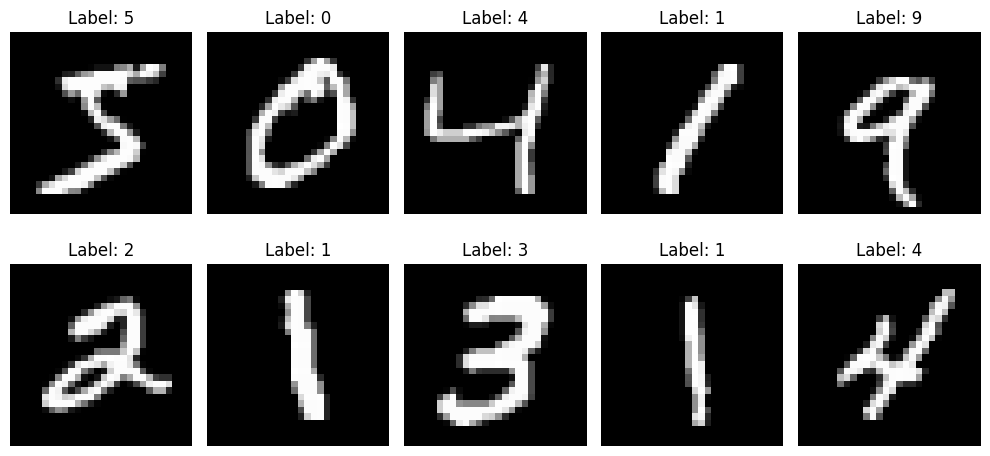

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Build CNN Model

model = tf.keras.Sequential([

    # First Convolutional Block
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu',
                           input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolutional Block
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten Layer
    tf.keras.layers.Flatten(),

    # Fully Connected Layer
    tf.keras.layers.Dense(64, activation='relu'),

    # Output Layer
    tf.keras.layers.Dense(10, activation='softmax')
])

# Display Model Architecture
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile CNN Model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [ ]:
# Train CNN Model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("CNN Training Completed Successfully!")

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9412 - loss: 0.1985 - val_accuracy: 0.9830 - val_loss: 0.0582
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9821 - loss: 0.0579 - val_accuracy: 0.9893 - val_loss: 0.0387
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9879 - loss: 0.0386 - val_accuracy: 0.9830 - val_loss: 0.0550
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9900 - loss: 0.0313 - val_accuracy: 0.9900 - val_loss: 0.0325
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9928 - loss: 0.0220 - val_accuracy: 0.9883 - val_loss: 0.0408
CNN Training Completed Successfully!


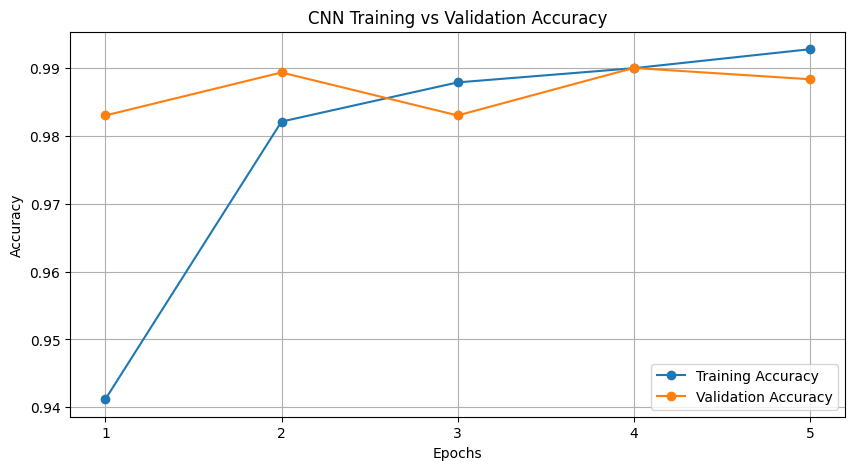

In [ ]:
# Plot Training and Validation Accuracy

plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'],
         marker='o',
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         marker='o',
         label='Validation Accuracy')

plt.title('CNN Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.xticks(range(5), range(1, 6))
plt.legend()
plt.grid(True)

plt.savefig('cnn_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

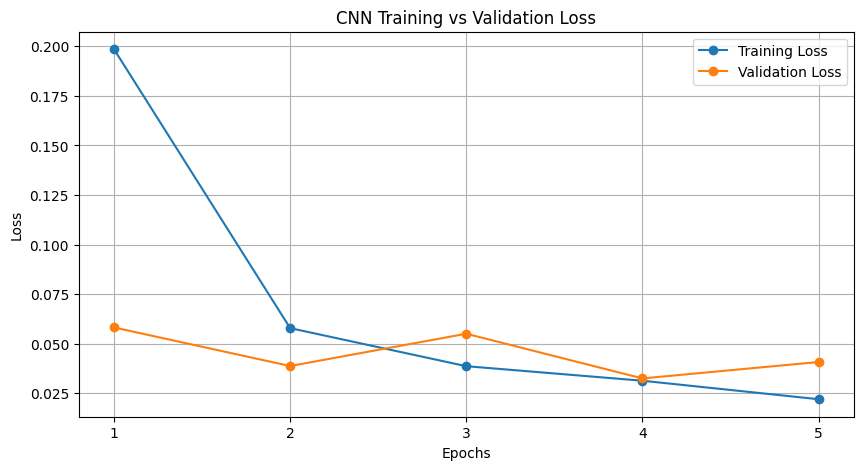

In [ ]:
# Plot Training and Validation Loss

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'],
         marker='o',
         label='Training Loss')

plt.plot(history.history['val_loss'],
         marker='o',
         label='Validation Loss')

plt.title('CNN Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.xticks(range(5), range(1, 6))
plt.legend()
plt.grid(True)

plt.savefig('cnn_loss.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Evaluate CNN Model

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)

print("CNN Test Loss:", test_loss)
print("CNN Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9879 - loss: 0.0379
CNN Test Loss: 0.03792697936296463
CNN Test Accuracy: 98.79000186920166 %


In [ ]:
# Save the trained CNN model

model.save('digit_cnn.keras')

print("CNN Model saved successfully!")

CNN Model saved successfully!


In [ ]:
from google.colab import files

files.download('digit_cnn.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# CNN Performance Summary

cnn_results = {
    "Model": "CNN (Keras)",
    "Test Loss": round(float(test_loss), 4),
    "Test Accuracy": round(float(test_accuracy * 100), 2)
}

print("CNN MODEL RESULTS")
print("-----------------------")

for key, value in cnn_results.items():
    print(f"{key}: {value}")

CNN MODEL RESULTS
-----------------------
Model: CNN (Keras)
Test Loss: 0.0379
Test Accuracy: 98.79


In [ ]:
import pandas as pd

# Store CNN results
cnn_accuracy = test_accuracy * 100

# Create comparison table
results = pd.DataFrame({
    "Evaluation Metric": ["Test Accuracy"],
    "CNN (Keras)": [f"{cnn_accuracy:.2f}%"]
})

print("CNN Model Performance")
display(results)

CNN Model Performance


,Evaluation Metric,CNN (Keras)
0,Test Accuracy,98.79%


In [ ]:
import pandas as pd

# Model comparison results

comparison = pd.DataFrame({
    "Model": ["SVM (Scikit-learn)", "CNN (Keras)"],
    "Dataset": ["MNIST", "MNIST"],
    "Test Accuracy (%)": [
        96.47,
        round(test_accuracy * 100, 2)
    ]
})

print("SVM vs CNN Performance Comparison")

display(comparison)

SVM vs CNN Performance Comparison


,Model,Dataset,Test Accuracy (%)
0,SVM (Scikit-learn),MNIST,96.47
1,CNN (Keras),MNIST,98.79


In [ ]:
# Save comparison results as CSV

comparison.to_csv("model_comparison.csv", index=False)

print("Comparison table saved successfully!")

display(comparison)

Comparison table saved successfully!


,Model,Dataset,Test Accuracy (%)
0,SVM (Scikit-learn),MNIST,96.47
1,CNN (Keras),MNIST,98.79


In [ ]:
from google.colab import files

files.download("model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>